# LuKARS 3.0 conceptual hydrological model

Intro 

In [1]:
# Load the libraries required by the notebook workflow.
from pathlib import Path
import re

import numpy as np
import numpy.ma as ma
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display
from SALib.sample import morris as morris_sample
from SALib.analyze import morris as morris_analyze

# Reusable LuKARS/model/helper functions are maintained in one module.
from lukars_functions import (
    run_model,
    read_config,
    fromCalibrationToPhysicalParameters,
    fromPhysicalToCalibrationParameters,
    save_output,
    nash_sutcliffe_efficiency,
)

# Project folders. Keep the Input and Output folders next to this notebook.
INPUT_DIR = Path("Input")
OUTPUT_DIR = Path("Output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 1- Input time series

In [2]:
## Load precipitation data
ts = pd.read_csv(
    INPUT_DIR / 'input_I_ET_SM_2001_2020.txt',
    sep='\t',
    index_col=0,
    decimal='.'
)

# Convert the index to datetime with the specified format
ts.index = pd.to_datetime(ts.index, format="%d/%m/%y")
# Extract the DateTime index as array
date_index = ts.index.to_numpy()

#nparray the values from the 'P' column
pr_0 = ts['S0'].values # it considers ET, I, SM
sns_0 = pr_0

pr = ts['S123'].values # it considers ET, I, SM
sns = pr

# convert Qobs to L/s
ts['QobsS'] = ts['QobsS'] / 1000 #* (1/(60*60*24))


## 2 - Model parameters and sampling 

### LOAD SETTINGS FROM CONFIG FILE 

In [3]:
config_file = INPUT_DIR / 'config.ini'
settings, config = read_config(config_file)


### STOCHASTIC PARAMETERS

In [4]:
# Detect hydrotope sections like [.Hydrotope 1], [.Hydrotope 2], ...
hydrotope_sections = [s for s in config.sections() if re.match(r"\.Hydrotope\s+\d+", s)]
hydrotope_ids = sorted([
    int(re.search(r"\.Hydrotope\s+(\d+)", s).group(1)) for s in hydrotope_sections
])

# Define parameter templates and transformations
param_template = [
    ('k_hyd', np.log), ('E_min', float), ('diff_E', float),
    ('alpha', float), ('k_is', np.log), ('k_sec', np.log), ('e_sec', float)
]

# Construct bounds and parameter names
_lbs, _ubs, param_names = [], [], []

for h in hydrotope_ids:
    section = f'.Hydrotope {h}'
    for param, transform in param_template:
        lb_key = f"{section}.{param}_lb"
        ub_key = f"{section}.{param}_ub"
        _lbs.append(transform(settings[lb_key]))
        _ubs.append(transform(settings[ub_key]))
        param_names.append(f"{param}_{h}")

# Base compartment (from [Stochastic])
_lbs.append(np.log(settings['Stochastic.kMS_lb']))
_ubs.append(np.log(settings['Stochastic.kMS_ub']))
param_names.append('kMS')

# Finalize arrays
_lbs = np.array(_lbs)
_ubs = np.array(_ubs)

In [5]:
_lbs


array([ 2.19722458e+00,  1.00000000e+01,  5.00000000e+00,  7.00000000e-01,
       -6.21460810e+00, -4.65646348e+00,  2.50000000e+01,  2.14006616e+00,
        4.00000000e+01,  4.00000000e+01,  5.00000000e-01, -7.50559228e+00,
       -6.07484616e+00,  1.30000000e+02,  2.04122033e+00,  7.50000000e+01,
        8.00000000e+01,  2.00000000e-01, -8.29404964e+00, -6.50229017e+00,
        3.20000000e+02, -1.00543104e+01])

### DETERMINISTIC PARAMETERS

In [6]:
dt = 1
nbCompartment = int(settings['Deterministic.nbCompartment'])
TotalArea = settings['Deterministic.TotalArea']

# Read ra and l_hyd arrays from the deterministic section
ra = np.array([settings[f'Deterministic.ra_{i+1}'] for i in range(nbCompartment)])
l_hyd = np.array([settings[f'Deterministic.l_hyd_{i+1}'] for i in range(nbCompartment)])

# Bottom compartment parameters from [Deterministic]
kMC = settings['Deterministic.kMC']
aMC = settings['Deterministic.aMC']
C_loss = settings['Deterministic.C_loss']
M_loss = settings['Deterministic.M_loss']
aMS = settings['Deterministic.aMS']
kCS = settings['Deterministic.kCS']
aCS = settings['Deterministic.aCS']

### MORRIS SAMPLING

In [7]:
t = settings['Morris.trajectories']
num_levels = settings['Morris.levels']
num_vars = len(param_names)

problem = {
    'num_vars': num_vars,
    'names': param_names,
    'bounds': [[-1, 1]] * num_vars
}

X = morris_sample.sample(problem, t, num_levels, seed=1234)
X_physical = fromCalibrationToPhysicalParameters(
    X,
    _lbs,
    _ubs,
    hydrotope_ids
)
X_physical_array = np.array(X_physical)


In [8]:
X_physical

{'k_hyd_1': array([ 41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.7742995, 900.       , 900.       ,
        900.       , 900.       , 900.       , 900.       , 900.       ,
        900.       , 900.       , 900.       , 900.       , 900.       ,
        900.       , 900.       , 900.       ,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
        900.       , 900.       , 900.       , 900.       , 900.       ,
        900.       , 900.       , 900.       , 900.       , 900.       ,
        900.       , 900.       , 900.       , 900.       ,  41.7742995,
         41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.7742995,  41.7742995,  41.7742995,
         41.7742995,  41.7742995,  41.77

### SAVE PARAMETER SAMPLES

In [9]:
for param, values in X_physical.items():
    save_output(param, values, output_dir=OUTPUT_DIR)

kis = np.array([X_physical[f'k_is_{h}'] for h in hydrotope_ids])
E_min = np.array([X_physical[f'E_min_{h}'] for h in hydrotope_ids])
E_max = np.array([X_physical[f'E_max_{h}'] for h in hydrotope_ids])
alpha = np.array([X_physical[f'alpha_{h}'] for h in hydrotope_ids])
k_hyd = np.array([X_physical[f'k_hyd_{h}'] for h in hydrotope_ids])
ksec = np.array([X_physical[f'k_sec_{h}'] for h in hydrotope_ids])
Esec = np.array([X_physical[f'e_sec_{h}'] for h in hydrotope_ids])
kMS = np.array(X_physical['kMS'])


## 3 - Flow model run

In [10]:
# Run the LuKARS model for all Morris parameter realizations.
#
# Binder-friendly memory handling:
# Only Q_sim is retained because the subsequent NSE, Morris and GLUE
# analyses use simulated spring discharge. 

num_runs = len(kMS)
num_time_steps = len(sns)

Q_sim = np.zeros((num_runs, num_time_steps))

for i in range(num_runs):
    kis_ = kis[:, i]
    E_min_ = E_min[:, i]
    E_max_ = E_max[:, i]
    alpha_ = alpha[:, i]
    k_hyd_ = k_hyd[:, i]
    ksec_ = ksec[:, i]
    Esec_ = Esec[:, i]
    kMS_ = kMS[i]

    run_up, run_bot = run_model(
        dt,
        sns_0,
        sns,
        1,
        1,
        1,
        ra,
        kis_,
        E_min_,
        E_max_,
        alpha_,
        k_hyd_,
        l_hyd,
        0,
        ksec_,
        Esec_,
        TotalArea,
        2900,
        0.5,
        kMC,
        aMC,
        C_loss,
        M_loss,
        kMS_,
        aMS,
        kCS,
        aCS,
    )

    # Q_sim is element 7 of the lower-compartment model output.
    Q_sim[i, :] = run_bot[7]


## 4 - Extract results

In [11]:
# Q_sim was extracted directly during the model ensemble run above.
# This avoids retaining unused state/flux arrays for every realization.
print("Number of Morris realizations:", Q_sim.shape[0])
print("Number of time steps:", Q_sim.shape[1])


Number of Morris realizations: 230
Number of time steps: 6939


### Save results

In [12]:
# save 2D arrays 
np.savetxt(OUTPUT_DIR / 'Q_sim.txt', Q_sim, delimiter='\t') # !!!!!!!!!!!!!!!!!!!!

## 5 - Computation of performance metric

In [13]:
Q_obs = ts.iloc[:,2] #/ 1000 # conversion from l/s to m3/s

# mask calibration period
Q_sim_cal = Q_sim[:, 1826:2921]
Q_obs_cal= Q_obs[1826:2921]
Q_obs_cal

date
2006-01-01    0.03370
2006-01-02    0.03354
2006-01-03    0.03356
2006-01-04    0.03359
2006-01-05    0.03348
               ...   
2008-12-26    0.03534
2008-12-27    0.03509
2008-12-28    0.03490
2008-12-29    0.03472
2008-12-30    0.03458
Name: QobsS, Length: 1095, dtype: float64

In [14]:
df_nse_value = pd.DataFrame()

for i in range(0,len(k_hyd[1])): 
    # Calculate NSE value for the current iteration
    nse_value = nash_sutcliffe_efficiency(Q_obs_cal, Q_sim_cal[i, :])

    # Add NSE value as a new column to the dataframe
    df_nse_value[f'nse_{i}'] = [nse_value]  

df_nse_value.to_csv(OUTPUT_DIR / 'df_nse.txt', sep='\t') 


C:\Users\beatr\AppData\Local\Temp\ipykernel_1740\369686693.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_nse_value[f'nse_{i}'] = [nse_value]
C:\Users\beatr\AppData\Local\Temp\ipykernel_1740\369686693.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_nse_value[f'nse_{i}'] = [nse_value]
C:\Users\beatr\AppData\Local\Temp\ipykernel_1740\369686693.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all c

In [15]:
df_nse_value

,nse_0,nse_1,nse_2,nse_3,nse_4,nse_5,nse_6,nse_7,nse_8,nse_9,...,nse_220,nse_221,nse_222,nse_223,nse_224,nse_225,nse_226,nse_227,nse_228,nse_229
0,-110.213856,-109.242717,-116.667534,-107.779487,-94.303967,-101.561304,-110.272929,-82.255329,-122.913367,-122.967049,...,-153.636509,-152.603088,-136.640413,-155.768071,-163.521516,-166.715144,-177.220475,-338.878294,-326.453724,-401.036173


## 6 - MORRIS

In [16]:
Y = df_nse_value.to_numpy().ravel()

# Run Morris sensitivity analysis
Si = morris_analyze.analyze(
    problem=problem,
    X=fromPhysicalToCalibrationParameters(
        X_physical,
        _lbs,
        _ubs,
        hydrotope_ids
    ),
    Y=Y,
    conf_level=0.95,
    print_to_console=True,
    num_levels=num_levels
)

# Build results DataFrame directly
df = pd.DataFrame({
    'param': Si['names'],
    'mu_star': ma.getdata(Si['mu_star']),
    'sigma': ma.getdata(Si['sigma'])
})

# Save results
df.to_csv(OUTPUT_DIR / 'Morris.txt', sep='\t', index=False)

                  mu     mu_star       sigma  mu_star_conf
k_hyd_1    -1.263829   18.985929   27.904042     10.406621
E_min_1     3.188710    4.970598    9.129184      4.680522
diff_E_1    4.361430    7.479812   11.774848      5.958176
alpha_1    -6.038949   10.259068   14.273834      7.200053
k_is_1      4.631514   15.285843   18.526123      6.692351
k_sec_1     0.687762    9.079413   13.327042      5.373001
e_sec_1     0.872100    5.711329    7.839075      2.794342
k_hyd_2    -6.384139   19.254831   34.741722     16.843716
E_min_2     0.174120    0.957407    1.823797      0.837174
diff_E_2    0.816071    2.634848    3.793212      1.553927
alpha_2    -7.314724    8.674070   19.299205      9.794834
k_is_2    -53.045828  110.474255  123.739684     40.986814
k_sec_2    23.371403   23.620148   37.913276     23.049002
e_sec_2     1.072857    2.462399    2.945378      1.144206
k_hyd_3   -48.478784  120.280065  174.069195     81.394451
E_min_3    -0.847972    1.283564    2.331457      1.3500

### Visualization 

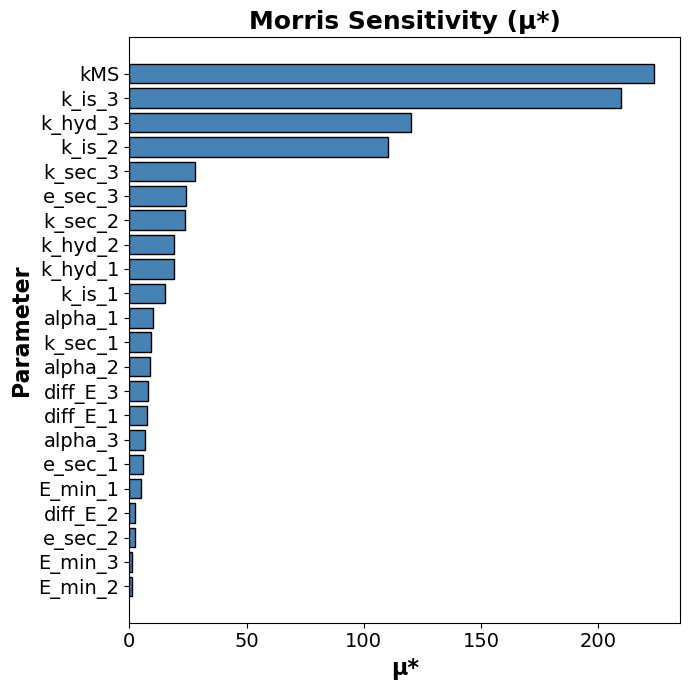

In [17]:
### to visualize the more sensitive parameters: bar chart of mu star

# Sort parameters by mu_star (descending makes most sensitive on top)
morris_results = df.sort_values(by='mu_star', ascending=True)

plt.figure(figsize=(7, 7))
plt.barh(
    y=morris_results['param'],
    width=morris_results['mu_star'],
    color='steelblue',
    edgecolor='black'
)

plt.title('Morris Sensitivity (μ*)', fontweight='bold', fontsize=18)
plt.xlabel('μ*', fontweight='bold', fontsize=16)
plt.ylabel('Parameter', fontweight='bold', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

# Save the figure
plt.savefig(OUTPUT_DIR / 'Morris_mu_star_bar.png', dpi=300, bbox_inches='tight')

plt.show()


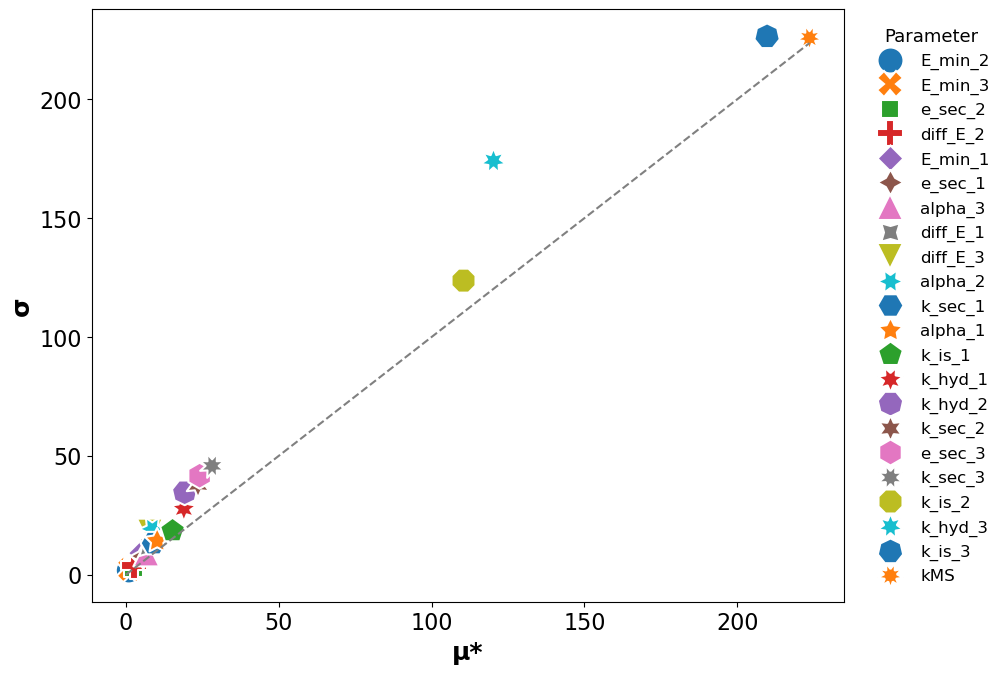

In [18]:
import seaborn as sns

plt.figure(figsize=(12, 7))

# Seaborn handles hue and style elegantly
sns.scatterplot(
    data=morris_results,
    x='mu_star',
    y='sigma',
    hue='param',
    style='param',
    s=350,
    palette='tab10'
)

# Axis labels and ticks
plt.xlabel("μ*", fontweight='bold', fontsize=18)
plt.ylabel("σ", fontweight='bold', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# 1:1 reference line
plt.plot(
    [0, morris_results['mu_star'].max()],
    [0, morris_results['mu_star'].max()],
    color='gray',
    linestyle='--'
)

# Legend on the right
plt.legend(
    title='Parameter',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    fontsize=12,
    title_fontsize=13,
    frameon=False
)

# Leave room for the legend
plt.tight_layout(rect=[0, 0, 0.85, 1])

# Save the figure
plt.savefig(OUTPUT_DIR / 'Morris_mu_star_sigma_scatter.png', dpi=300, bbox_inches='tight')

plt.show()


## 7 - Select and plot the Morris realization with the NSE closer to 1 (best fitting the observations) 

In [19]:
# Get NSE values from dataframe
nse_values = df_nse_value.iloc[0]

# Find the index of the simulation with the highest NSE
best_idx = nse_values.idxmax()

# Convert column name such as "nse_12" to integer index 12
best_sim_number = int(best_idx.split("_")[-1])

# Get best NSE value
best_nse = nse_values[best_idx]

print("Best Morris simulation:", best_sim_number)
print("Best NSE:", best_nse)

# Get corresponding best simulated discharge
best_Qsim = Q_sim[best_sim_number, :]

# Save best NSE
pd.DataFrame({
    "best_simulation": [best_sim_number],
    "NSE": [best_nse]
}).to_csv(
    OUTPUT_DIR / 'best_Morris_NSE.txt',
    sep="\t",
    index=False
)

# Save corresponding parameters
best_parameters = pd.DataFrame({
    "parameter": list(X_physical.keys()),
    "value": [X_physical[p][best_sim_number] for p in X_physical.keys()]
})

best_parameters.to_csv(
    OUTPUT_DIR / 'best_Morris_parameters.txt',
    sep="\t",
    index=False
)

display(best_parameters)

# Save observed and simulated discharge 
pd.DataFrame({
    "date": ts.index,
    "Qobs": Q_obs,
    "Qsim": best_Qsim
}).to_csv(
    OUTPUT_DIR / 'best_Morris_Qobs_Qsim.txt',
    sep="\t",
    index=False
)


Best Morris simulation: 157
Best NSE: -0.7313812247185585


,parameter,value
0,k_hyd_1,900.000000
1,E_min_1,36.666667
2,E_max_1,61.666667
3,alpha_1,1.000000
4,k_is_1,0.009283
5,k_sec_1,0.204671
6,e_sec_1,25.000000
7,k_hyd_2,183.126949
8,E_min_2,66.666667
9,E_max_2,133.333333


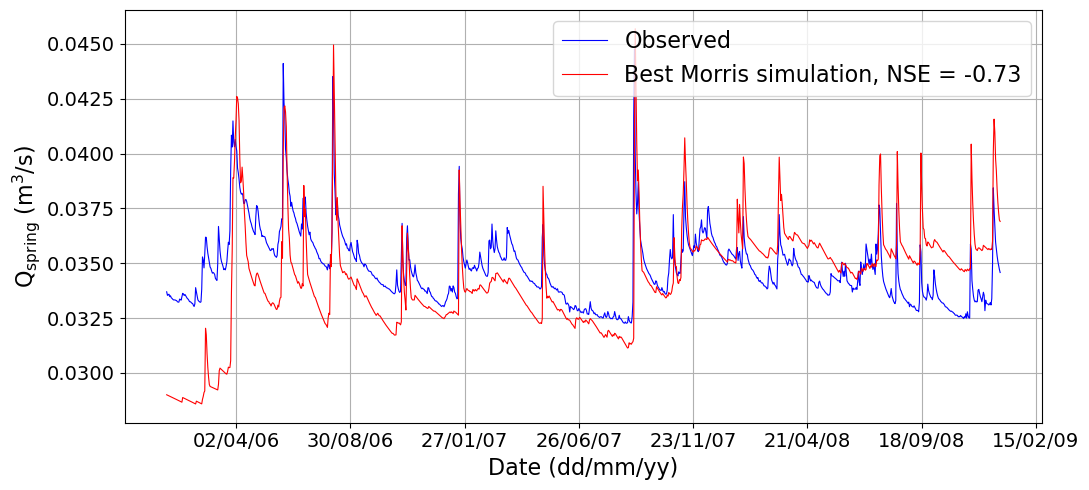

In [20]:
# --------------------------
# Plot observed vs best Qsim
# --------------------------
# Period to plot
start_idx = 1826
end_idx = 2921


fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    ts.index[start_idx:end_idx],
    Q_obs[start_idx:end_idx],
    color="blue",
    label="Observed",
    linewidth=0.8
)

ax.plot(
    ts.index[start_idx:end_idx],
    best_Qsim[start_idx:end_idx],
    color="red",
    label=f"Best Morris simulation, NSE = {best_nse:.2f}",
    linewidth=0.8
)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=150))

ax.set_xlabel("Date (dd/mm/yy)", fontsize=16)
ax.set_ylabel(r"Q$_{\mathrm{spring}}$ (m$^3$/s)", fontsize=16)

plt.legend(loc="upper right", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / 'best_Morris_Qobs_Qsim_selected_period.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8 - Uncertanty bands defined as the interquartile and 10/90 percentile of the Morris realizations with NSE > 0.5 

In [21]:
# NSE threshold
nse_threshold = 0.5

# Select simulations with NSE larger than 0.5
selected_nse = df_nse_value.iloc[0][df_nse_value.iloc[0] > nse_threshold]

print("Number of simulations with NSE > 0.5:", len(selected_nse))

# Only calculate uncertainty bands when behavioural realizations exist.
if len(selected_nse) == 0:
    print("No behavioural realizations at this NSE threshold; GLUE bands will be skipped.")
else:
    # Convert selected column names, such as nse_12, into simulation indexes
    selected_sim_numbers = [
        int(col.split("_")[-1]) for col in selected_nse.index
    ]

    # Save selected simulations and NSE values
    pd.DataFrame({
        "simulation": selected_sim_numbers,
        "NSE": selected_nse.values
    }).to_csv(
        OUTPUT_DIR / 'Morris_simulations_NSE_gt_05.txt',
        sep="\t",
        index=False
    )

    # Get only selected simulated discharges
    selected_Qsim = Q_sim[selected_sim_numbers, :]

    # Save selected simulated discharges for selected period only
    pd.DataFrame(
        selected_Qsim[:, start_idx:end_idx].T,
        index=ts.index[start_idx:end_idx]
    ).to_csv(
        OUTPUT_DIR / 'Qsim_Morris_NSE_gt_05_selected_period.txt',
        sep="\t"
    )

    # ------------------------------------------------------------
    # Compute uncertainty bands only from simulations with NSE > 0.5
    # ------------------------------------------------------------

    Qsim_selected_df = pd.DataFrame(
        selected_Qsim[:, start_idx:end_idx].T,
        index=ts.index[start_idx:end_idx]
    )

    uncertainty_bands = pd.DataFrame(index=ts.index[start_idx:end_idx])

    uncertainty_bands["min"] = Qsim_selected_df.min(axis=1)
    uncertainty_bands["max"] = Qsim_selected_df.max(axis=1)
    uncertainty_bands["10%"] = Qsim_selected_df.quantile(0.10, axis=1)
    uncertainty_bands["25%"] = Qsim_selected_df.quantile(0.25, axis=1)
    uncertainty_bands["50%"] = Qsim_selected_df.quantile(0.50, axis=1)
    uncertainty_bands["75%"] = Qsim_selected_df.quantile(0.75, axis=1)
    uncertainty_bands["90%"] = Qsim_selected_df.quantile(0.90, axis=1)

    # Save uncertainty bands
    uncertainty_bands.to_csv(
        OUTPUT_DIR / 'Morris_uncertainty_bands_NSE_gt_05_selected_period.txt',
        sep="\t"
    )



Number of simulations with NSE > 0.5: 0
No behavioural realizations at this NSE threshold; GLUE bands will be skipped.


In [22]:
if len(selected_nse) > 0:
    # ------------------------
    # Plot uncertainty bands
    # ------------------------

    # Period to plot
    start_idx = 1826
    end_idx = 2921


    fig, ax = plt.subplots(figsize=(11, 5))

    ax.fill_between(
        uncertainty_bands.index,
        uncertainty_bands["min"],
        uncertainty_bands["max"],
        color="lightgray",
        alpha=0.6,
        label="Range"
    )

    ax.fill_between(
        uncertainty_bands.index,
        uncertainty_bands["10%"],
        uncertainty_bands["90%"],
        color="gray",
        alpha=0.6,
        label="10-90% Percentile"
    )

    ax.fill_between(
        uncertainty_bands.index,
        uncertainty_bands["25%"],
        uncertainty_bands["75%"],
        color="red",
        alpha=0.3,
        label="25-75% Interquartile"
    )

    ax.plot(
        uncertainty_bands.index,
        uncertainty_bands["50%"],
        color="black",
        linewidth=0.8,
        label="Median"
    )

    ax.plot(
        ts.index[start_idx:end_idx],
        Q_obs[start_idx:end_idx],
        color="blue",
        linewidth=0.8,
        label="Observed"
    )

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=150))

    ax.set_xlabel("Date (dd/mm/yy)", fontsize=16)
    ax.set_ylabel(r"Q$_{\mathrm{spring}}$ (m$^3$/s)", fontsize=16)

    plt.legend(loc="upper right", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / 'Morris_uncertainty_bands_NSE_gt_05_selected_period.png',
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()